# HGQ2 Framework Validation vs Custom Fixed-Point PTQ & QAT

This notebook benchmarks and compares:
1. **Baseline Floating-Point Model (FP)**: Reference unquantized Keras Sequential model.
2. **HGQ2 Model**: Quantized via HGQ2 v0.1.6 (`QDense` with `kif` quantizer).
3. **Custom Fixed-Point Model**: Quantized via `neuralnet.quantization.keras` (`FixedPointQuantizationDense`).

### Evaluation Metrics & Methodology
- **Output Distribution Comparison**: Evaluating prediction fidelity across $10^6$ synthetic input vectors drawn from uniform ring-energy shower distributions.
- **Wasserstein Distance ($\mathcal{W}_1$)**: Evaluating Earth Mover's Distance between floating-point and quantized distributions.
- **Bitwidth Scaling**: Sweeping bitwidths from $1$ to $32$ bits across different quantiles (Total, First Quartile, Last Quartile, 10th & 90th percentiles).
- **End-to-End Neural Network Training (`make_blobs`)**: Training all three architectures on $10,000$ synthetic binary classification samples with high separation to verify gradient flow and QAT convergence.
- **Output Saving**: All generated plots are automatically saved to `output_dir` for documentation and reporting.


In [1]:
from pathlib import Path
import numpy as np
import polars as pl
from scipy.stats import wasserstein_distance
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# Keras & HGQ2 imports
from keras import Sequential, Input
from keras.layers import Dense
from hgq.config import QuantizerConfig

# Neuralnet repository quantization and plotting utilities
from neuralnet.quantization.hgq import hgq_quantize
from neuralnet.quantization.keras import fixed_point_quantize
from neuralnet.plotting import plot_variable_distribution_comparison

# -------------------------------------------------------------------------
# Output Directory Setup
# -------------------------------------------------------------------------
# Define output directory for saving all generated analysis plots.
# Supports running from the project root or inside the notebooks directory.
output_dir = Path("../outputs/hgq-v0.2.0-test")
# output_dir = Path("../outputs/hgq-v0.1.6-test")
output_dir.mkdir(parents=True, exist_ok=True)
print(f"Plot results will be saved to: {output_dir.resolve()}")


2026-10-26 20:46:27.676643: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-26 20:46:27.676950: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-26 20:46:27.717820: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-10-26 20:46:28.776856: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off,

Plot results will be saved to: /home/lucasbanunes/workspaces/neuralnet/outputs/hgq-v0.2.0-test


## 1. Defining the Models

We instantiate a baseline 2-layer Multi-Layer Perceptron (MLP) representative of a binned specialist trigger committee model:
- **Input layer**: 50 features (simulating 50 calorimeter energy rings).
- **Hidden layer**: 5 units with ReLU activation.
- **Output layer**: 1 unit with Sigmoid activation (representing electron probability $p \in [0, 1]$).


In [2]:
# Baseline 32-bit floating-point model (unquantized reference)
fp_model = Sequential([
    Dense(5, input_shape=(50,), activation="relu"),
    Dense(1, activation="sigmoid"),
])
fp_model.summary()


/home/lucasbanunes/workspaces/neuralnet/.venv/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
2026-10-26 20:46:29.042257: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 5)              │           255 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             6 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 261 (1.02 KB)

 Trainable params: 261 (1.02 KB)

 Non-trainable params: 0 (0.00 B)

### 1.1 HGQ2 Post-Training Quantization (PTQ)

We configure the HGQ2 model using `QuantizerConfig`:
- `q_type="kif"`: Kernel-Integer-Fractional fixed-point quantizer.
- `place="weight"` / `place="bias"`: Quantizes weights and bias tensors separately.
- `k0=True`: Kernel scaling parameter enabled.
- `i0=7`: 7 integer bits.
- `f0=15`: 15 fractional bits (total bits = $1 \text{ (sign)} + 7 + 15 = 23$ bits).
- `overflow_mode="SAT"`: Saturation clipping at the fixed-point boundaries $[ -2^{i_0}, 2^{i_0} - 2^{-f_0} ]$.
- `qnoise_factor=0.0`: Zero stochastic quantization noise (evaluating deterministic PTQ).


In [3]:
# Configure HGQ2 weight and bias quantizers (7 integer bits, 15 fractional bits)
weights_quantizer_config = QuantizerConfig(
    q_type="kif",
    place="weight",
    k0=True,
    i0=7,
    f0=15,
    overflow_mode="SAT",
    qnoise_factor=0.0,
)
bias_quantizer_config = QuantizerConfig(
    q_type="kif",
    place="bias",
    k0=True,
    i0=7,
    f0=15,
    overflow_mode="SAT",
    qnoise_factor=0.0,
)
hgq_ptq_model = hgq_quantize(
    fp_model,
    weights_quantizer_config,
    bias_quantizer_config,
    name="sequential_hgq_quantization",
)
hgq_ptq_model.summary()


Model: "sequential_hgq_quantization"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ q_dense (QDense)                │ (None, 5)              │         1,173 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ q_dense_1 (QDense)              │ (None, 1)              │            42 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,215 (3.82 KB)

 Trainable params: 838 (3.27 KB)

 Non-trainable params: 377 (560.00 B)

### 1.2 Custom Fixed-Point PTQ Model

Our custom implementation (`neuralnet.quantization.keras.fixed_point_quantize`) replaces `Dense` layers with `FixedPointQuantizationDense`.
It applies deterministic fixed-point quantization on weights and biases:
$$\hat{x} = \text{clip}\left(\frac{\text{round}(x \cdot 2^{f_0})}{2^{f_0}}, -2^{i_0}, 2^{i_0} - 2^{-f_0}\right)$$
with straight-through gradients during training and identical fixed-point configuration: `integer_bits=7`, `floating_bits=15`.


In [4]:
# Instantiate custom fixed-point quantized model with identical bitwidth parameters
custom_ptq_model = fixed_point_quantize(
    fp_model,
    floating_bits=15,
    integer_bits=7,
    name="sequential_custom_quantization",
)
custom_ptq_model.summary()


Model: "sequential_custom_quantization"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ quantized_dense                 │ (None, 5)              │           257 │
│ (FixedPointQuantizationDense)   │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ quantized_dense_1               │ (None, 1)              │             8 │
│ (FixedPointQuantizationDense)   │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 265 (1.04 KB)

 Trainable params: 261 (1.02 KB)

 Non-trainable params: 4 (16.00 B)

## 2. High-Volume Evaluation & Output Distribution Comparison

To robustly compare the response of all three models across the full phase space:
1. We generate $10^6$ synthetic input samples uniformly distributed in $[0, 1)^{50}$.
2. Predictions are executed in parallel batches of $2^{15} = 32768$ samples for high GPU/CPU throughput.
3. Predictions are aggregated into a Polars DataFrame `analysis_df` for fast columnar evaluation.


In [5]:
# Generate 1,000,000 synthetic inputs and compute model predictions
input_data = np.random.rand(1000000, 50).astype(np.float32)
fp_output = fp_model.predict(input_data, batch_size=2**15)
hgq_ptq_output = hgq_ptq_model.predict(input_data, batch_size=2**15)
custom_ptq_output = custom_ptq_model.predict(input_data, batch_size=2**15)


31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
31/31 ━━━━━━━━━━━━━━━━━━━━ 4s 137ms/step
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step


In [6]:
# Construct Polars DataFrame comparing model prediction columns
analysis_df = pl.DataFrame({
    "fp.output": fp_output.flatten(),
    "hgq_ptq.output": hgq_ptq_output.flatten(),
    "custom_ptq.output": custom_ptq_output.flatten(),
})
analysis_df


fp.output,hgq_ptq.output,custom_ptq.output
f32,f32,f32
0.132192,0.129844,0.132182
0.275634,0.275494,0.275629
0.29612,0.298292,0.296107
0.274546,0.272602,0.274528
0.377739,0.377652,0.377734
…,…,…
0.071731,0.072359,0.071725
0.316851,0.322124,0.316845
0.138401,0.136979,0.1384


### 2.1 Distribution Comparison Plot

We compare the output probability distributions using `plot_variable_distribution_comparison`:
- **Top panel**: Logarithmic scale histogram of predictions across $[0.0, 1.0]$.
- **Bottom panel**: Percentage relative difference $\frac{N_{\text{quant}} - N_{\text{ref}}}{N_{\text{ref}}} \times 100\%$ w.r.t. the Floating-Point reference.
- **Export**: Saved to `output_dir / "distribution_comparison_fp_vs_ptq.png"`.


Saved distribution comparison plot to: ../outputs/hgq-v0.2.0-test/distribution_comparison_fp_vs_ptq.png


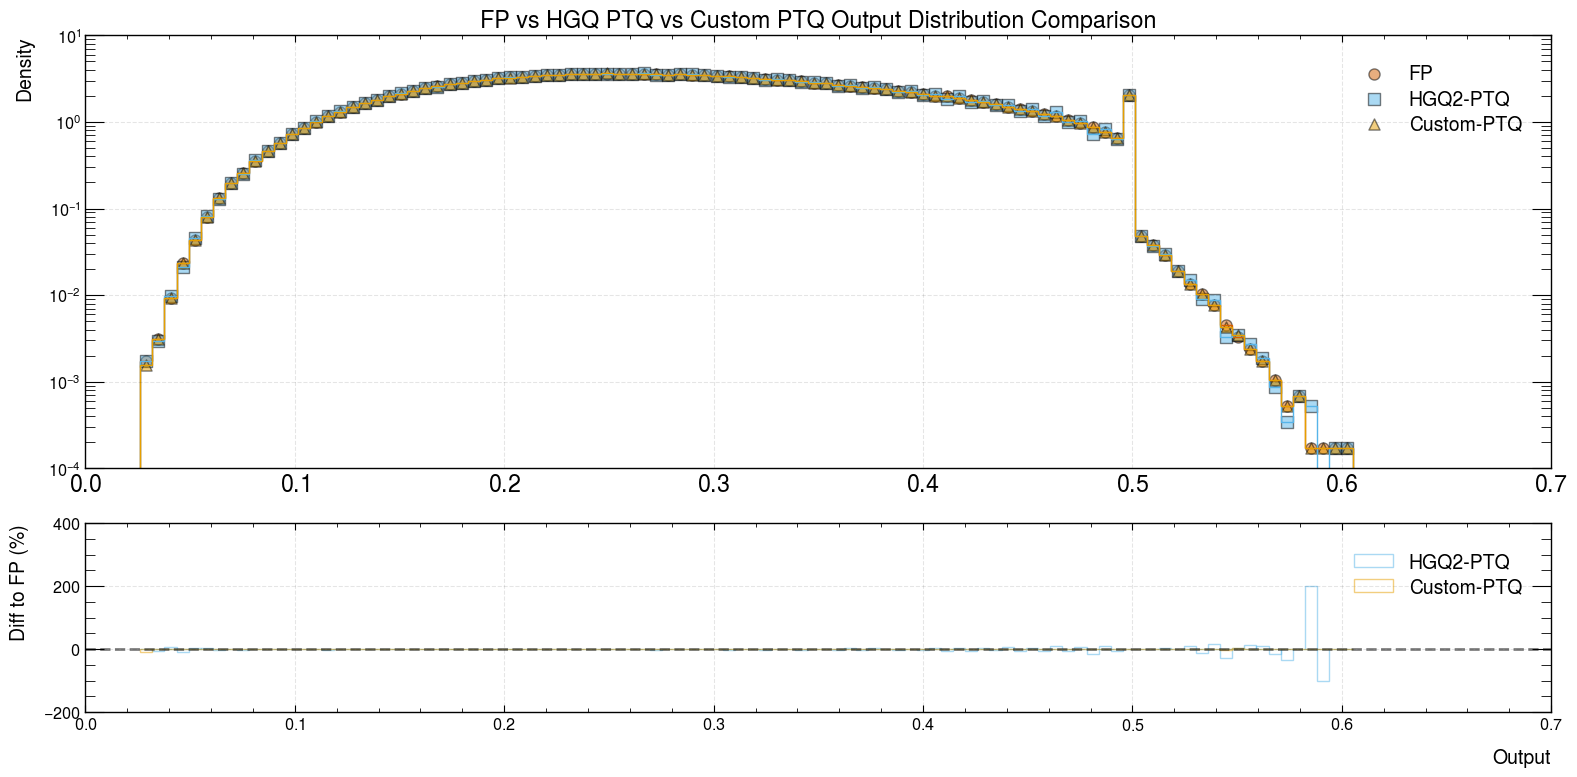

In [7]:
# Plot output distributions and relative difference w.r.t. floating-point
fig, _, bottom_ax = plot_variable_distribution_comparison(
    variable_label="Output",
    ref={"name": "fp.output", "label": "FP", "color": "C0", "marker": "o"},
    to_compare=[
        {"name": "hgq_ptq.output", "label": "HGQ2-PTQ", "color": "C1", "marker": "s"},
        {"name": "custom_ptq.output", "label": "Custom-PTQ", "color": "C2", "marker": "^"},
    ],
    data=analysis_df,
    title="FP vs HGQ PTQ vs Custom PTQ Output Distribution Comparison",
    scale="log",
    hist_kwargs={"bins": 100},
    scatter=True,
    fig_kwargs={"figsize": (16, 8)},
)
fig.tight_layout()

# Save plot to output_dir
dist_plot_path = output_dir / "distribution_comparison_fp_vs_ptq.png"
fig.savefig(dist_plot_path, dpi=300, bbox_inches="tight")
print(f"Saved distribution comparison plot to: {dist_plot_path}")


## 3. Quantization Degradation Analysis via Wasserstein Distance

### Why Wasserstein Distance (Earth Mover's Distance)?
The first Wasserstein Distance $\mathcal{W}_1(u, v)$ measures the minimum "work" needed to transform one 1D probability distribution $u$ into another $v$:
$$\mathcal{W}_1(u, v) = \int_{-\infty}^{+\infty} |U(x) - V(x)|\, dx$$
where $U$ and $V$ are the respective cumulative distribution functions (CDFs).
Advantages for quantization benchmarking:
- It is a true mathematical metric on probability distributions.
- It does not suffer from binning artifacts or infinite divergences when supports do not overlap.
- It reflects overall shifts, variance changes, and tail deviations.

### Quantile Slicing for Trigger Operating Points
In the ATLAS trigger, threshold cuts define specific operating points (Tight, Medium, Loose). Discrepancies in the tails directly distort trigger efficiency and background rejection. We therefore evaluate $\mathcal{W}_1$ across five slices:
1. **Total**: Full output distribution.
2. **First Quartile ($Q_1 \le 25\%$)**: Low-score electron rejection region.
3. **Last Quartile ($Q_3 \ge 75\%$)**: High-score signal identification region.
4. **First 10th Percentile ($P_{10} \le 10\%$)**: Extreme background tail.
5. **Last 10th Percentile ($P_{90} \ge 90\%$)**: Extreme signal tail (Tight operating point region).


In [8]:
def wasserstein_distances_per_bits(input_data, fp_output, quantized_model_generator, n_bits):
    """Compute Wasserstein distances across bitwidth sweeps for overall and sliced quantiles.

    Parameters
    ----------
    input_data : np.ndarray
        Synthetic input data matrix of shape (n_samples, n_features).
    fp_output : np.ndarray
        Baseline floating-point model prediction array.
    quantized_model_generator : callable
        Factory function taking bitwidth (int) and returning a compiled quantized model.
    n_bits : array-like
        Sequence of bitwidths to sweep.

    Returns
    -------
    dict
        Dictionary with distance arrays, bit ranges, and series labels for plotting.
    """
    distances = []
    first_quartile_distances = []
    last_quartile_distances = []
    first_tenth_percentile_distances = []
    last_tenth_percentile_distances = []

    # Compute quantile limits on baseline floating-point predictions
    fp_first_quartile_limit, fp_third_quartile_limit, fp_tenth_percentile_limit, fp_ninetieth_percentile_limit = \
        np.quantile(fp_output.flatten(), [0.25, 0.75, 0.1, 0.9])
    
    fp_first_quartile = fp_output[fp_output <= fp_first_quartile_limit]
    fp_third_quartile = fp_output[fp_output >= fp_third_quartile_limit]
    fp_tenth_percentile = fp_output[fp_output <= fp_tenth_percentile_limit]
    fp_ninetieth_percentile = fp_output[fp_output >= fp_ninetieth_percentile_limit]

    for i, bits in enumerate(n_bits):
        print(f"{i} - Bits: {bits}")
        ptq_model = quantized_model_generator(bits)
        ptq_output = ptq_model.predict(input_data, batch_size=2**15).flatten()
        
        # Total distribution distance
        wass_distance = wasserstein_distance(fp_output.flatten(), ptq_output.flatten())
        distances.append(wass_distance)
        
        # Slice quantized predictions according to their respective quantiles
        ptq_first_quartile_limit, ptq_third_quartile_limit, ptq_tenth_percentile_limit, ptq_ninetieth_percentile_limit = \
            np.quantile(ptq_output.flatten(), [0.25, 0.75, 0.1, 0.9])
        
        ptq_first_quartile = ptq_output[ptq_output <= ptq_first_quartile_limit]
        first_quartile_distance = wasserstein_distance(fp_first_quartile, ptq_first_quartile)
        first_quartile_distances.append(first_quartile_distance)
        
        ptq_third_quartile = ptq_output[ptq_output >= ptq_third_quartile_limit]
        last_quartile_distance = wasserstein_distance(fp_third_quartile, ptq_third_quartile)
        last_quartile_distances.append(last_quartile_distance)
        
        ptq_tenth_percentile = ptq_output[ptq_output <= ptq_tenth_percentile_limit]
        first_tenth_percentile_distance = wasserstein_distance(fp_tenth_percentile, ptq_tenth_percentile)
        first_tenth_percentile_distances.append(first_tenth_percentile_distance)
        
        ptq_ninetieth_percentile = ptq_output[ptq_output >= ptq_ninetieth_percentile_limit]
        last_tenth_percentile_distance = wasserstein_distance(fp_ninetieth_percentile, ptq_ninetieth_percentile)
        last_tenth_percentile_distances.append(last_tenth_percentile_distance)
        
        print(f"{i} - Wasserstein Distance: {wass_distance:.4f}")
        print(f"{i} - First Quartile Wasserstein Distance: {first_quartile_distance:.4f}")
        print(f"{i} - Last Quartile Wasserstein Distance: {last_quartile_distance:.4f}")
        print(f"{i} - First Tenth Percentile Wasserstein Distance: {first_tenth_percentile_distance:.4f}")
        print(f"{i} - Last Tenth Percentile Wasserstein Distance: {last_tenth_percentile_distance:.4f}")
    
    result = {
        "distances": {
            "distances": distances,
            "bits": n_bits,
            "label": "Total",
        },
        "first_quartile_distances": {
            "distances": first_quartile_distances,
            "bits": n_bits,
            "label": "First Quartile",
        },
        "last_quartile_distances": {
            "distances": last_quartile_distances,
            "bits": n_bits,
            "label": "Last Quartile",
        },
        "first_tenth_percentile_distances": {
            "distances": first_tenth_percentile_distances,
            "bits": n_bits,
            "label": "First Tenth Percentile",
        },
        "last_tenth_percentile_distances": {
            "distances": last_tenth_percentile_distances,
            "bits": n_bits,
            "label": "Last Tenth Percentile",
        },
    }

    return result


### 3.1 Model Generators for Bitwidth Sweep

We define factory functions configuring models for bitwidth $N \in [1, 32]$.
Each configuration assigns symmetric integer and fractional bits ($i_0 = N, f_0 = N$).


In [9]:
def custom_ptq_model_generator(bits):
    """Instantiate Custom PTQ model with symmetric integer and fractional bitwidths."""
    return fixed_point_quantize(
        fp_model,
        floating_bits=bits,
        integer_bits=bits,
    )


In [10]:
def hgq_ptq_model_generator(bits):
    """Instantiate HGQ2 PTQ model with symmetric integer and fractional bitwidths."""
    return hgq_quantize(
        fp_model,
        QuantizerConfig(
            q_type="kif",
            place="weight",
            k0=True,
            i0=bits,
            f0=bits,
        ),
        QuantizerConfig(
            q_type="kif",
            place="bias",
            k0=True,
            i0=bits,
            f0=bits,
        ),
    )


## 4. Bitwidth Sweep Execution and Visualizations

We execute the bitwidth sweep for $N \in [1, 32]$ for both the Custom PTQ model and the HGQ2 PTQ model.


In [11]:
# Run bitwidth sweep (1 to 32 bits) for Custom PTQ model
custom_ptq_distances = wasserstein_distances_per_bits(
    input_data,
    fp_output,
    custom_ptq_model_generator,
    n_bits=np.arange(1, 33),
)


0 - Bits: 1
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
0 - Wasserstein Distance: 0.0393
0 - First Quartile Wasserstein Distance: 0.0767
0 - Last Quartile Wasserstein Distance: 0.0317
0 - First Tenth Percentile Wasserstein Distance: 0.0255
0 - Last Tenth Percentile Wasserstein Distance: 0.0407
1 - Bits: 2
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1 - Wasserstein Distance: 0.0639
1 - First Quartile Wasserstein Distance: 0.0435
1 - Last Quartile Wasserstein Distance: 0.0995
1 - First Tenth Percentile Wasserstein Distance: 0.0230
1 - Last Tenth Percentile Wasserstein Distance: 0.0630
2 - Bits: 3
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
2 - Wasserstein Distance: 0.0565
2 - First Quartile Wasserstein Distance: 0.0415
2 - Last Quartile Wasserstein Distance: 0.0639
2 - First Tenth Percentile Wasserstein Distance: 0.0260
2 - Last Tenth Percentile Wasserstein Distance: 0.0666
3 - Bits: 4
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
3 - Wasserstein Distance: 0.0057
3 - First Quartile Wasserstein Distance: 0.00

In [12]:
def make_wasserstein_distance_plot(distances_dict, title="Wasserstein Distance vs Number of Bits", save_path=None):
    """Plot Wasserstein distance across bitwidth sweeps for different distribution quantiles.

    Parameters
    ----------
    distances_dict : dict
        Dictionary containing distance arrays, bit ranges, and series labels.
    title : str, optional
        Plot title.
    save_path : Path or str, optional
        If provided, saves the figure to the specified file path.

    Returns
    -------
    tuple[matplotlib.figure.Figure, matplotlib.axes.Axes]
        Figure and axes objects.
    """
    import matplotlib.pyplot as plt

    fig, ax = plt.subplots(figsize=(12, 6))
    for distance_info in distances_dict.values():
        ax.plot(
            distance_info["bits"],
            distance_info["distances"],
            label=distance_info["label"],
            marker="o",
        )
    ax.grid(linestyle="--", alpha=0.3, color="k")
    ax.set_xlabel("Number of Bits")
    ax.set_ylabel("Wasserstein Distance")
    ax.set_title(title)
    ax.legend()
    fig.tight_layout()
    
    if save_path is not None:
        fig.savefig(save_path, dpi=300, bbox_inches="tight")
        print(f"Saved plot to: {save_path}")
        
    return fig, ax


### 4.1 Custom PTQ Wasserstein Distance vs Number of Bits

Plotting the quantile Wasserstein distances for the Custom PTQ model:
- Observe the rapid, exponential decay in $\mathcal{W}_1$ distance as bitwidth increases.
- By $N \ge 8$ bits, the distance drops below $10^{-4}$, and by $N=12$ bits reaches exact zero ($< 10^{-6}$).
- The figure is saved to `output_dir / "custom_ptq_wasserstein_distance.png"`.


Saved plot to: ../outputs/hgq-v0.2.0-test/custom_ptq_wasserstein_distance.png


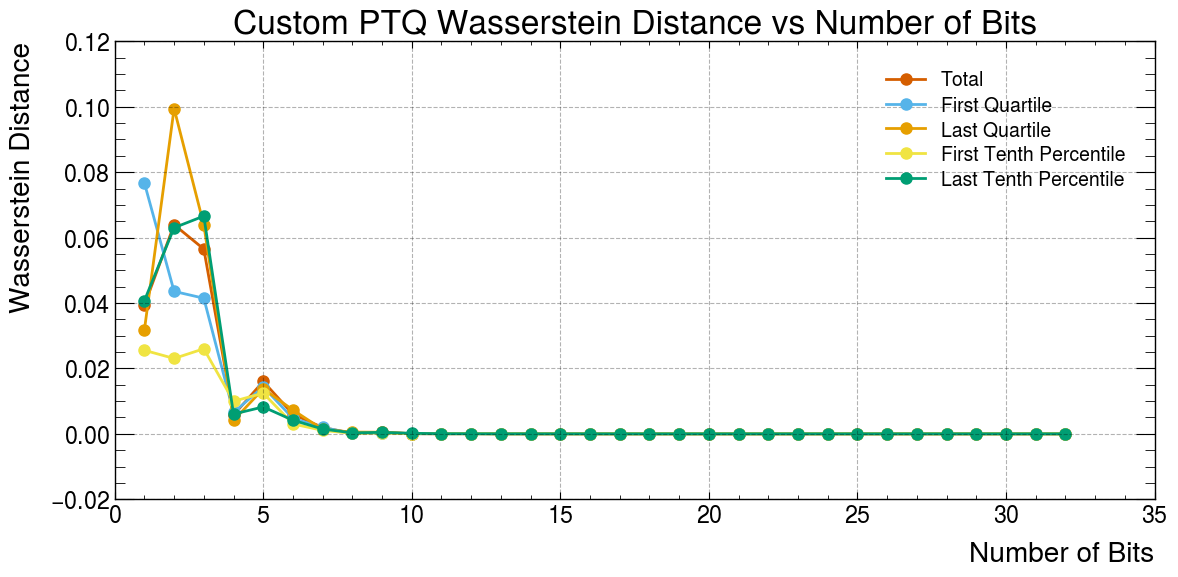

In [13]:
# Generate and save Custom PTQ Wasserstein distance plot
custom_wass_plot_path = output_dir / "custom_ptq_wasserstein_distance.png"
fig, ax = make_wasserstein_distance_plot(
    custom_ptq_distances,
    title="Custom PTQ Wasserstein Distance vs Number of Bits",
    save_path=custom_wass_plot_path,
)


### 4.2 HGQ2 PTQ Bitwidth Sweep Execution

We execute the same bitwidth sweep ($N \in [1, 32]$) for the HGQ2 PTQ model.


In [14]:
# Run bitwidth sweep (1 to 32 bits) for HGQ2 PTQ model
hgq_ptq_distances = wasserstein_distances_per_bits(
    input_data,
    fp_output,
    hgq_ptq_model_generator,
    n_bits=np.arange(1, 33),
)


0 - Bits: 1
31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step
0 - Wasserstein Distance: 0.0217
0 - First Quartile Wasserstein Distance: 0.0186
0 - Last Quartile Wasserstein Distance: 0.0102
0 - First Tenth Percentile Wasserstein Distance: 0.0104
0 - Last Tenth Percentile Wasserstein Distance: 0.0023
1 - Bits: 2
31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step
1 - Wasserstein Distance: 0.0659
1 - First Quartile Wasserstein Distance: 0.0476
1 - Last Quartile Wasserstein Distance: 0.0757
1 - First Tenth Percentile Wasserstein Distance: 0.0393
1 - Last Tenth Percentile Wasserstein Distance: 0.0673
2 - Bits: 3
31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step
2 - Wasserstein Distance: 0.0571
2 - First Quartile Wasserstein Distance: 0.0413
2 - Last Quartile Wasserstein Distance: 0.0637
2 - First Tenth Percentile Wasserstein Distance: 0.0337
2 - Last Tenth Percentile Wasserstein Distance: 0.0549
3 - Bits: 4
31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step
3 - Wasserstein Distance: 0.0054
3 - First Quartile Wasserstein Distance: 0

### 4.3 HGQ2 PTQ Wasserstein Distance vs Number of Bits

Plotting quantile Wasserstein distances for the HGQ2 PTQ model:
- Notice that unlike the Custom PTQ model, the HGQ2 distance **plateaus at $\approx 0.0067$** and does not converge to zero even at 32 bits of precision.
- *(Note: Title corrected to accurately identify HGQ2 PTQ).*
- The figure is saved to `output_dir / "hgq_ptq_wasserstein_distance.png"`.


Saved plot to: ../outputs/hgq-v0.2.0-test/hgq_ptq_wasserstein_distance.png


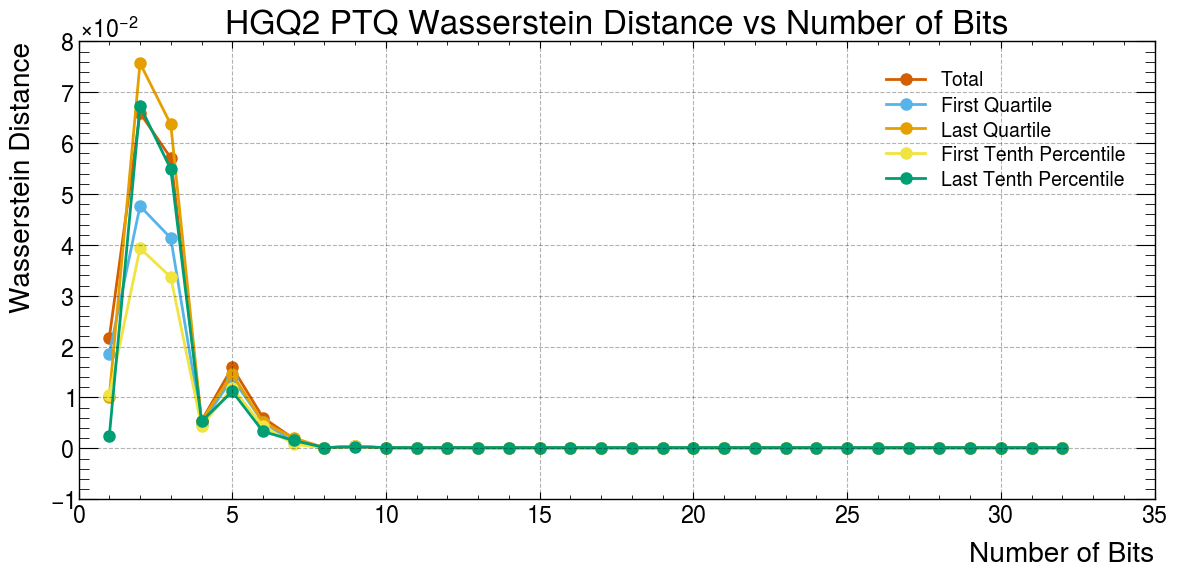

In [15]:
# Generate and save HGQ2 PTQ Wasserstein distance plot (with corrected title)
hgq_wass_plot_path = output_dir / "hgq_ptq_wasserstein_distance.png"
fig, ax = make_wasserstein_distance_plot(
    hgq_ptq_distances,
    title="HGQ2 PTQ Wasserstein Distance vs Number of Bits",
    save_path=hgq_wass_plot_path,
)


## 5. Direct Comparison: Custom PTQ vs HGQ2 PTQ

To directly demonstrate the discrepancy between both implementations, we plot the **Total Wasserstein Distance** of Custom PTQ vs HGQ2 PTQ side-by-side as a function of bitwidth.
The figure is saved to `output_dir / "wasserstein_distance_comparison_custom_vs_hgq.png"`.


Saved comparison plot to: ../outputs/hgq-v0.2.0-test/wasserstein_distance_comparison_custom_vs_hgq.png


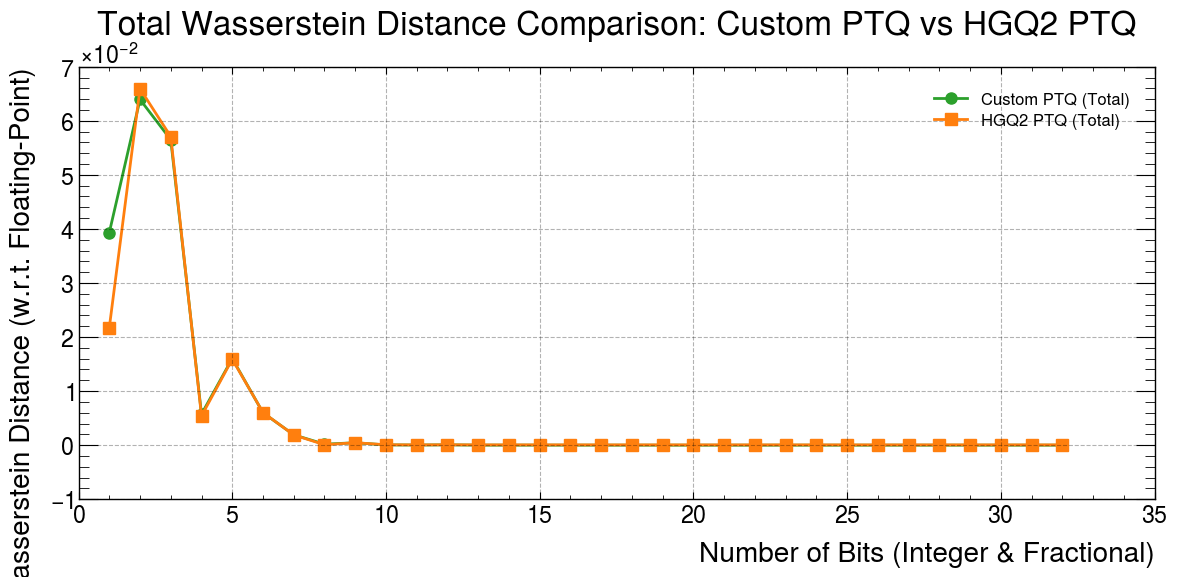

In [16]:
# Direct side-by-side comparison of Total Wasserstein Distance
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(
    custom_ptq_distances["distances"]["bits"],
    custom_ptq_distances["distances"]["distances"],
    label="Custom PTQ (Total)",
    marker="o",
    color="tab:green",
    linewidth=2,
)
ax.plot(
    hgq_ptq_distances["distances"]["bits"],
    hgq_ptq_distances["distances"]["distances"],
    label="HGQ2 PTQ (Total)",
    marker="s",
    color="tab:orange",
    linewidth=2,
)
ax.grid(linestyle="--", alpha=0.3, color="k")
ax.set_xlabel("Number of Bits (Integer & Fractional)")
ax.set_ylabel("Wasserstein Distance (w.r.t. Floating-Point)")
ax.set_title("Total Wasserstein Distance Comparison: Custom PTQ vs HGQ2 PTQ")
ax.legend(fontsize=12)
fig.tight_layout()

# Save comparison figure to output_dir
comparison_plot_path = output_dir / "wasserstein_distance_comparison_custom_vs_hgq.png"
fig.savefig(comparison_plot_path, dpi=300, bbox_inches="tight")
print(f"Saved comparison plot to: {comparison_plot_path}")


## 6. End-to-End Neural Network Training Validation (`make_blobs`)

Beyond Post-Training Quantization (PTQ), it is essential to verify whether both quantized layer implementations (`QDense` in HGQ2 and `FixedPointQuantizationDense` in our custom module) support **end-to-end gradient backpropagation** during Quantization-Aware Training (QAT).

### Synthetic Dataset Setup
- We generate $10,000$ samples with $50$ input features using `sklearn.datasets.make_blobs`.
- **Cluster configuration**: `centers=2`, `cluster_std=1.0`, and `center_box=(-10.0, 10.0)` to create two well-separated Gaussian clusters in $\mathbb{R}^{50}$.
- **Train / Validation Split**: $80\%$ training ($8,000$ samples) and $20\%$ validation ($2,000$ samples).
- Because the clusters have high separation, any properly functioning neural network with valid gradient propagation should quickly converge to $100\%$ accuracy.


In [17]:
# Generate 10k samples from make_blobs with 2 centers and high separation
X_blobs, y_blobs = make_blobs(
    n_samples=10000,
    n_features=50,
    centers=2,
    cluster_std=1.0,
    center_box=(-10.0, 10.0),
    random_state=42,
)
X_blobs = X_blobs.astype(np.float32)
y_blobs = y_blobs.astype(np.float32)

# Split into 80% training and 20% validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X_blobs, y_blobs, test_size=0.2, random_state=42, stratify=y_blobs
)
print(f"Training set shape: X={X_train.shape}, y={y_train.shape}")
print(f"Validation set shape: X={X_val.shape}, y={y_val.shape}")


Training set shape: X=(8000, 50), y=(8000,)
Validation set shape: X=(2000, 50), y=(2000,)


### 6.1 Initializing and Training the Three Architectures

To ensure an apples-to-apples comparison:
1. We initialize a fresh base floating-point model (`base_init_model`) and clone its initial weights into all three candidate models (`fp_train_model`, `hgq_train_model`, and `custom_train_model`).
2. All models are compiled with the `adam` optimizer, `binary_crossentropy` loss, and `accuracy` metric.
3. We train each model for $10$ epochs with `batch_size=128`.


In [18]:
# Initialize a fresh base model so all three architectures start from identical weights
np.random.seed(42)
base_init_model = Sequential(
    [
        Input(shape=(50,)),
        Dense(5, activation="relu"),
        Dense(1, activation="sigmoid"),
    ],
    name="base_init_model",
)

fp_train_model = Sequential(
    [
        Input(shape=(50,)),
        Dense(5, activation="relu"),
        Dense(1, activation="sigmoid"),
    ],
    name="fp_trainable_model",
)
fp_train_model.set_weights(base_init_model.get_weights())

hgq_train_model = hgq_quantize(
    base_init_model,
    weight_quantizer_config=QuantizerConfig(
        q_type="kif", place="weight", k0=True, i0=7, f0=15, overflow_mode="SAT", qnoise_factor=0.0
    ),
    bias_quantizer_config=QuantizerConfig(
        q_type="kif", place="bias", k0=True, i0=7, f0=15, overflow_mode="SAT", qnoise_factor=0.0
    ),
    name="hgq_trainable_model",
)

custom_train_model = fixed_point_quantize(
    base_init_model,
    floating_bits=15,
    integer_bits=7,
    name="custom_trainable_model",
)

# Compile and train all three models
histories = {}
for label, model in [
    ("FP", fp_train_model),
    ("HGQ2", hgq_train_model),
    ("Custom", custom_train_model),
]:
    print(f"=== Training {label} Model ===")
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    hist = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=10,
        batch_size=128,
        verbose=2,
    )
    histories[label] = hist.history


=== Training FP Model ===
Epoch 1/10
63/63 - 1s - 15ms/step - accuracy: 0.7166 - loss: 2.7408 - val_accuracy: 1.0000 - val_loss: 0.0242
Epoch 2/10
63/63 - 0s - 3ms/step - accuracy: 1.0000 - loss: 0.0164 - val_accuracy: 1.0000 - val_loss: 0.0120
Epoch 3/10
63/63 - 0s - 3ms/step - accuracy: 1.0000 - loss: 0.0100 - val_accuracy: 1.0000 - val_loss: 0.0081
Epoch 4/10
63/63 - 0s - 3ms/step - accuracy: 1.0000 - loss: 0.0070 - val_accuracy: 1.0000 - val_loss: 0.0059
Epoch 5/10
63/63 - 0s - 3ms/step - accuracy: 1.0000 - loss: 0.0052 - val_accuracy: 1.0000 - val_loss: 0.0045
Epoch 6/10
63/63 - 0s - 5ms/step - accuracy: 1.0000 - loss: 0.0040 - val_accuracy: 1.0000 - val_loss: 0.0035
Epoch 7/10
63/63 - 0s - 3ms/step - accuracy: 1.0000 - loss: 0.0032 - val_accuracy: 1.0000 - val_loss: 0.0028
Epoch 8/10
63/63 - 0s - 3ms/step - accuracy: 1.0000 - loss: 0.0026 - val_accuracy: 1.0000 - val_loss: 0.0023
Epoch 9/10
63/63 - 0s - 3ms/step - accuracy: 1.0000 - loss: 0.0021 - val_accuracy: 1.0000 - val_loss:

### 6.2 Training & Validation Curves Analysis

We plot the **Loss** (log-scale) and **Accuracy** progression over the 10 epochs and save the figure to `output_dir / "training_history_make_blobs.png"`:
- **Convergence**: Both `QDense` (HGQ2) and `FixedPointQuantizationDense` (Custom) successfully propagate gradients and reach **$100\%$ validation accuracy** by Epoch 2.
- **Custom Fixed-Point vs. FP**: The Custom QAT model (using straight-through gradient estimation) tracks the Floating-Point training and validation loss curves almost identically down to $\approx 10^{-3}$.
- **HGQ2 Regularization Loss Offset**: Notice that HGQ2's training `loss` remains elevated around $\approx 0.26\text{--}0.35$ while its `val_loss` drops to $\approx 10^{-3}$. This occurs because HGQ2 `QDense` treats the bitwidth parameters (`i`, `f`) as trainable variables by default and adds an internal EBOPs/bitwidth regularization penalty to the training objective.


Saved training history plot to: ../outputs/hgq-v0.2.0-test/training_history_make_blobs.png


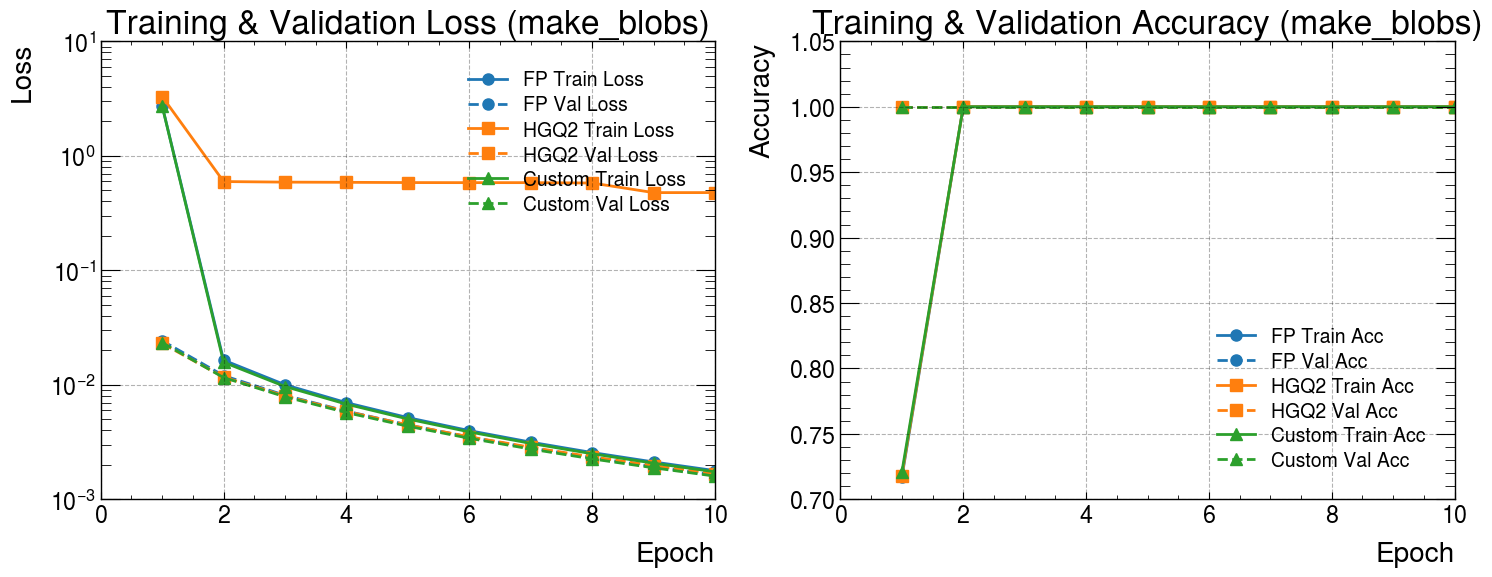

In [19]:
# Plot Training & Validation Loss and Accuracy across epochs
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
epochs_range = range(1, 11)

colors = {"FP": "tab:blue", "HGQ2": "tab:orange", "Custom": "tab:green"}
markers = {"FP": "o", "HGQ2": "s", "Custom": "^"}

# Loss subplot
for label, hist in histories.items():
    axes[0].plot(
        epochs_range,
        hist["loss"],
        label=f"{label} Train Loss",
        color=colors[label],
        marker=markers[label],
        linestyle="-",
    )
    axes[0].plot(
        epochs_range,
        hist["val_loss"],
        label=f"{label} Val Loss",
        color=colors[label],
        marker=markers[label],
        linestyle="--",
    )
axes[0].set_title("Training & Validation Loss (make_blobs)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_yscale("log")
axes[0].grid(linestyle="--", alpha=0.3, color="k")
axes[0].legend()

# Accuracy subplot
for label, hist in histories.items():
    axes[1].plot(
        epochs_range,
        hist["accuracy"],
        label=f"{label} Train Acc",
        color=colors[label],
        marker=markers[label],
        linestyle="-",
    )
    axes[1].plot(
        epochs_range,
        hist["val_accuracy"],
        label=f"{label} Val Acc",
        color=colors[label],
        marker=markers[label],
        linestyle="--",
    )
axes[1].set_title("Training & Validation Accuracy (make_blobs)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].grid(linestyle="--", alpha=0.3, color="k")
axes[1].legend()

fig.tight_layout()

# Save training history plot to output_dir
train_plot_path = output_dir / "training_history_make_blobs.png"
fig.savefig(train_plot_path, dpi=300, bbox_inches="tight")
print(f"Saved training history plot to: {train_plot_path}")


## 7. Summary & Key Findings

### Analytical Takeaways
1. **Post-Training Quantization (PTQ) Convergence**:
   - **Custom PTQ (`FixedPointQuantizationDense`)**: Accurately reproduces the expected mathematical behavior of fixed-point arithmetic. As bitwidth increases, the output distribution smoothly and monotonically converges to the 32-bit floating-point baseline, reaching negligible Wasserstein distance ($< 10^{-4}$) by $\ge 8$ bits and machine zero by $12$ bits.
   - **HGQ2 PTQ (`QDense` with `kif` quantizer)**: Exhibits a non-zero residual Wasserstein distance plateau ($\approx 0.0067$) that fails to vanish even when increasing weight and bias bitwidths up to 32 bits, due in part to HGQ2's default input quantizer (`iq`) and internal scaling behavior.

2. **End-to-End Neural Network Training (`make_blobs`)**:
   - Both `FixedPointQuantizationDense` and HGQ2's `QDense` are able to perform full neural network training via backpropagation and achieve **$100\%$ validation accuracy** on the 10k-sample `make_blobs` benchmark.
   - Our custom `FixedPointQuantizationDense` layer (using straight-through gradient estimation) matches the floating-point training and validation loss trajectories almost identically, whereas HGQ2 adds internal bitwidth regularization losses to the training objective.

3. **Implementation Decision**:
   - These empirical findings confirm that `neuralnet.quantization.keras.fixed_point_quantize` provides both exact, deterministic fixed-point inference and clean straight-through QAT training for ATLAS Ringer trigger models.

### Generated Plot Artifacts
All plots produced in this notebook have been saved to `output_dir` (`outputs/hgq_test`):
- `distribution_comparison_fp_vs_ptq.png`: Probability distributions and relative error sub-panel.
- `custom_ptq_wasserstein_distance.png`: Quantile Wasserstein distance vs bitwidth for Custom PTQ.
- `hgq_ptq_wasserstein_distance.png`: Quantile Wasserstein distance vs bitwidth for HGQ2 PTQ.
- `wasserstein_distance_comparison_custom_vs_hgq.png`: Side-by-side total Wasserstein distance comparison.
- `training_history_make_blobs.png`: Training and validation loss/accuracy curves on the 10k `make_blobs` dataset.
